<a href="https://colab.research.google.com/github/Shxrp08/Project_SG_I-Smile_Group6_2026/blob/main/Project_SG_Group_6_Rev3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ML Regression Model

### Library yg Hrs Dipanggil:

In [ ]:
# Manipulasi Data dan Visual

import pandas as pd                                                              #Baca file CSV, ngolah isi data tabel, cari missing value
import numpy as np                                                               #Operasi matrix n array
import matplotlib.pyplot as plt                                                  #bikin tampilan gambar bewarna
import seaborn as sns                                                            #grafik warna-warni (penyempurna matplotlib)

#Pre-processing dan pemisahan data

from sklearn.model_selection import (
    train_test_split,                                                            # rasio train dan test; text_size=0.XX untuk skala 100-XX : XX
    cross_val_score                                                              # bagi data latih: cv=X, model dilatih X kali dr semua data latih yg dibagi X
)
from sklearn.preprocessing import (
    StandardScaler,                                                              # Feature scaling: standarisasi
    MinMaxScaler,                                                                # Feature scaling: normalisasi
    OneHotEncoder,                                                               # text kategori nominal (gada tingkatan) jadi kolom biner 0/1
    OrdinalEncoder                                                               # kategori tingkatan jadi 0,1,2,3,...
)
from sklearn.compose import ColumnTransformer                                    #gabung teknik olah data berbeda (scaling, encoding), dlm satu alur
from sklearn.pipeline import Pipeline                                            #bungkus ColumnTransformer dan model ML jadi 1 paket biar gada data leakage

#Algoritma model regresi

from sklearn.ensemble import RandomForestRegressor                               #Random Forest (regresi)
from sklearn.linear_model import LinearRegression                                #Linear Regression
from sklearn.tree import DecisionTreeRegressor                                   #Decision Tree (regresi)

#metrik evaluasi regresi

from sklearn.metrics import (
    mean_squared_error,                                                          # MSE
    mean_absolute_error,                                                         # MAE
    r2_score                                                                     # R^2
)


                                                    
### Memasukkan dataset yang mau digunakan (sebagai Data Path)

In [ ]:
#DATA_PATH
DATA_PATH = "/content/ai_student_impact_dataset (1)-selected-columns.csv"        #Path dari dataset yang akan digunakan

 #  df = data frame, pd = pandas
df = pd.read_csv(DATA_PATH)                                                      # Membaca data
print("Ukuran data (baris, kolom):", df.shape)                                   # df.shape: menunjukkan berapa banyak baris dan kolom pada csv
df.head(15) #default = 5                                                         # Menampilkan berapa banyak indeks data yang akan ditampilkan pada kolom

Ukuran data (baris, kolom): (50000, 10)


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55
5,100006,STEM,Junior,3.449,6.50,Debugging/Troubleshooting,Beginner,1,False,14.19
6,100007,STEM,Freshman,3.622,31.41,Summarizing_Reading,Advanced,5,True,13.11
7,100008,Arts,Junior,2.746,5.33,Copywriting/Drafting,Intermediate,3,False,18.45
8,100009,Business,Sophomore,3.420,2.00,Debugging/Troubleshooting,Beginner,2,True,2.87
9,100010,Business,Sophomore,3.046,19.99,Debugging/Troubleshooting,Intermediate,2,True,12.49



### Menampilkan tipe data dan jumlah nilai non-null (nilai tidak kosong)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                50000 non-null  int64  
 1   Major_Category            50000 non-null  object 
 2   Year_of_Study             50000 non-null  object 
 3   Pre_Semester_GPA          50000 non-null  float64
 4   Weekly_GenAI_Hours        50000 non-null  float64
 5   Primary_Use_Case          50000 non-null  object 
 6   Prompt_Engineering_Skill  50000 non-null  object 
 7   Tool_Diversity            50000 non-null  int64  
 8   Paid_Subscription         50000 non-null  bool   
 9   Traditional_Study_Hours   50000 non-null  float64
dtypes: bool(1), float64(3), int64(2), object(4)
memory usage: 3.5+ MB



### Keterangan Tipe data kolom

| Kolom | Makna | Keterangan |
|---|---|---|
|`Student_ID`|Identitas Mahasiswa (berupa angka)|
|`Major_Kategory`|Jurusan mahasiswa|
|`Year_of_Study`|Derajat tingkatan mahasiswa|Freshman(Tahun 1), Sophomore(Tahun 2), Junior(Tahun 3), Senior(Tahun 4), Graduate(Lulusan)|
|`Pre_Semester_GPA`|IPK mahasiswa|pre-semester berarti IPK sebelum memasuki semester atau periode pengambilan data|
|`Weekly_GenAI_Hours`|Berapa jam penggunaan GenAI per-minggu|
|`Primary_Use_Case`|Tujuan penggunaan GenAI|
|`Prompt_Engineering_Skill`|tingkat kemahiran dalam prompting|prompting: menyusun instruksi ke komputer (AI)|
|`Tool_Diversity`|variasi banyaknya tool AI yang dipake|
|`Paid_Subscription`|apakah mahasiswa memakai layanan berbayar|
|`Traditional_Study_Hours`|berapa jam perminggu mahasiswa belajar biasa|belajar mandiri tanpa AI|

## A. EDA (Exploratory Data Analysis)


###1. Analisis Satu Variabel (value_counts)

In [ ]:
# Kita bisa memakai fungsi value_counts untuk menghitung jumlah baris data (frekuensi) untuk setiap kategori

# misal, kita ambil dua kategori: Major_Category dan Year_of_Study

display(df["Major_Category"].value_counts())
display(df["Year_of_Study"].value_counts())

# kalau gk pake fungsi display dan menulis kedua panggilan dengan

#df["Year_of_Study"].value_counts()
#df["Major_Category"].value_counts()

#ipynb cuma bakal jalanin perintah terbawah!

,count
Major_Category,
STEM,15059
Business,12538
Humanities,9994
Medical,6476
Arts,5933


,count
Year_of_Study,
Junior,11045
Freshman,11031
Senior,10634
Sophomore,9860
Graduate,7430


In [ ]:
# value_counts bisa juga buat tipe data selain kategori. tapi untuk kasus yang mungkin memiliki sangat banyak variasi (kayak float yang detail),
# kita berikan parameter bins untuk memberi batas rentang!

display(df["Pre_Semester_GPA"].value_counts(bins=5).reset_index().rename(columns={"index": "Pre_Semester_GPA (Rentang)", "Pre_Semester_GPA (Rentang)": "Count"}))
print("\n\n")
display(df["Pre_Semester_GPA"].value_counts(bins=5))

,Pre_Semester_GPA (Rentang),count
0,"(2.872, 3.435]",20525
1,"(3.435, 3.998]",15907
2,"(2.309, 2.872]",10602
3,"(1.746, 2.309]",2717
4,"(1.179, 1.746]",249


,count
"(2.872, 3.435]",20525
"(3.435, 3.998]",15907
"(2.309, 2.872]",10602
"(1.746, 2.309]",2717
"(1.179, 1.746]",249


####Perilaku Tanpa bins (Diskrit):
  - Pada data diskrit/kategori, Pandas menyimpan nama kolom asal (Pre_Semester_GPA) sebagai nama dari Index-nya. Saat dirender oleh Jupyter, header index-nya ikut tercetak di atas.
####Perilaku Pakai bins (Kontinu):
  - Saat kamu pakai parameter bins=5, Pandas menggunakan fungsi pembantu bernama pd.cut() di latar belakang untuk memotong angka kontinu jadi interval rentang (2.872, 3.435]. Hasil potongannya menghasilkan tipe objek baru bernama IntervalIndex.

  - Nah, objek IntervalIndex buatan Pandas ini secara default tidak memiliki atribut nama (name=None). Makanya di tabel bawah pada gambarmu, bagian atas rentang angka itu terlihat kosong mlompong dan cuma ada header count di atas frekuensinya.

In [ ]:
#Versi persentase untuk value_counts

(df["Primary_Use_Case"].value_counts(normalize=True) * 100).round(2)

# Normalize=True digunakan untuk merubah nilai desimal ke persentase
# Round(X) digunkan untuk membulatkan X angka dibelakang koma

,proportion
Primary_Use_Case,
Debugging/Troubleshooting,24.59
Copywriting/Drafting,24.02
Ideation,21.44
Summarizing_Reading,17.27
Direct_Answer_Generation,12.68


###2. Visualisasi

####2a. Membuat Histogram

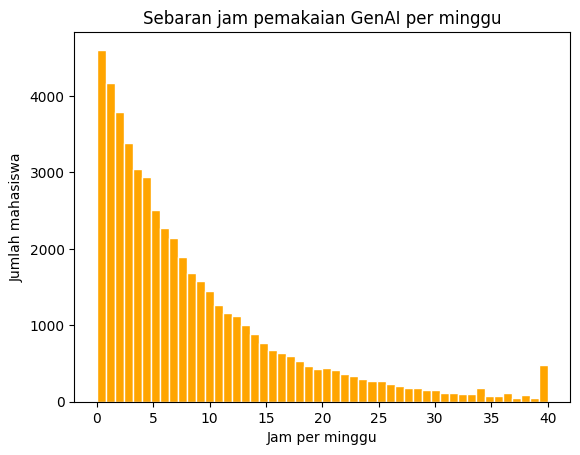

In [ ]:
# Misal, kita membuat histogram terkait distribusi jam pemakaian GenAI per minggu dari informasi pada Weekly_GenAI_Hours yang ada di csv

# plt = pyplot

plt.hist(df["Weekly_GenAI_Hours"], bins=50, color="orange", edgecolor="white")      #plt.hist: membuat grafik histogram
plt.title("Sebaran jam pemakaian GenAI per minggu")                                 #plt.title: membuat judul dari histogram
plt.xlabel("Jam per minggu")                                                        #plt.xlabel: membuat nilai pada sumbu x
plt.ylabel("Jumlah mahasiswa")                                                      #plt.ylabel: membuat nilai pada sumbu y
plt.show()                                                                          #plt.show: menampilkan grafiknya

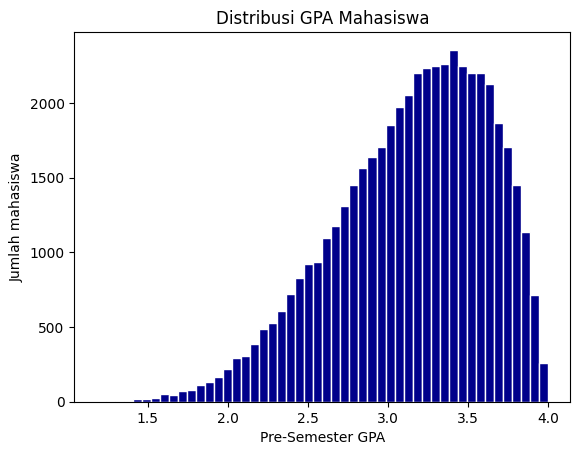

In [ ]:
# Misal, histogram terkait distribusi IPK(GPA) mahasiswa pre-semester yang ada pada tipe data Pre_Semester_GPA

plt.hist(df["Pre_Semester_GPA"], bins=50, color="darkblue", edgecolor="white")  #membuat histogram
plt.title("Distribusi GPA Mahasiswa")                                           #judul histogram
plt.xlabel("Pre-Semester GPA")                                                  #informasi sumbu x
plt.ylabel("Jumlah mahasiswa")                                                  #informasi sumbu y
plt.show()                                                                      #menampilkan histogram

####2b. Conditional Counting: cek baris spesifik

In [ ]:
#Misal, dari histogram sebelumnya, kita mencari berapa banyak mahasiswa dengan GPA X dengan parameter Pre_Semester_GPA

jumlah_mahasiswa_ipk = (df["Pre_Semester_GPA"] >= 3.5).sum()
print("Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5:", jumlah_mahasiswa_ipk)

Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5: 13346


In [ ]:
#Bisa dicari dengan cara lain, seperti berikut:

print("Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5::", (df["Pre_Semester_GPA"] >= 3.5).sum())


Jumlah mahasiswa ber GPA lebih sama dengan dari 3.5:: 13346


####2c. Mean/Median/Modus

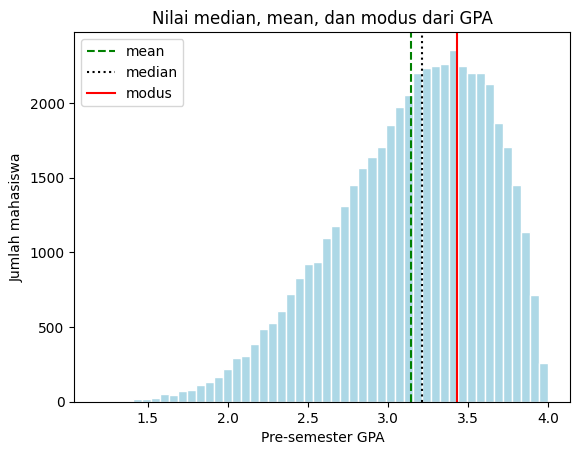

In [ ]:

plt.hist(df["Pre_Semester_GPA"], bins=50, color="lightblue", edgecolor="white")
plt.axvline(df["Pre_Semester_GPA"].mean(), color="green", linestyle="--", label="mean")
plt.axvline(df["Pre_Semester_GPA"].median(), color="black", linestyle=":", label="median")
plt.axvline(df["Pre_Semester_GPA"].mode()[0], color="red", linestyle="-", label="modus")      #[0] berarti modus ke 0 (0,1,2,...), karena modus bisa lebih dari satu
plt.title("Nilai median, mean, dan modus dari GPA")                                           # kalau selain [0] mendapat error, maka modus memang cuma 1
plt.xlabel("Pre-semester GPA")
plt.ylabel("Jumlah mahasiswa")
plt.legend()
plt.show()

####2d. Scatter plot/Grafik titik

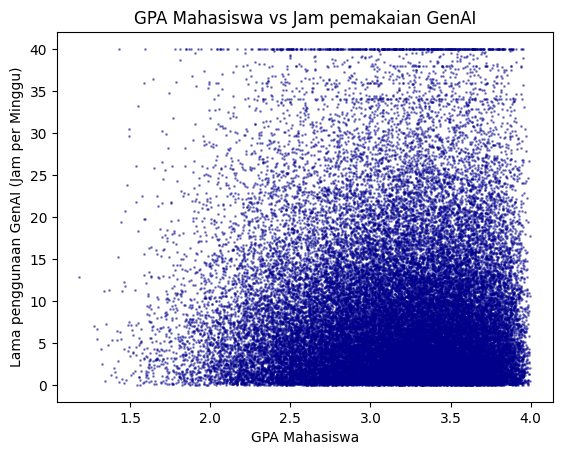

In [ ]:
# Hubungan GPA Mahasiswa dengan Sebaran jam pemakaian GenAI per minggu

plt.scatter(df["Pre_Semester_GPA"], df["Weekly_GenAI_Hours"], alpha=0.4, s=1, color="darkblue")  # Atur scatter: alpha = transparansi,  s = size
plt.title("GPA Mahasiswa vs Jam pemakaian GenAI")
plt.xlabel("GPA Mahasiswa")
plt.ylabel("Lama penggunaan GenAI (Jam per Minggu)")
plt.show()

####2e. Boxplot/Diagram Kotak-garis

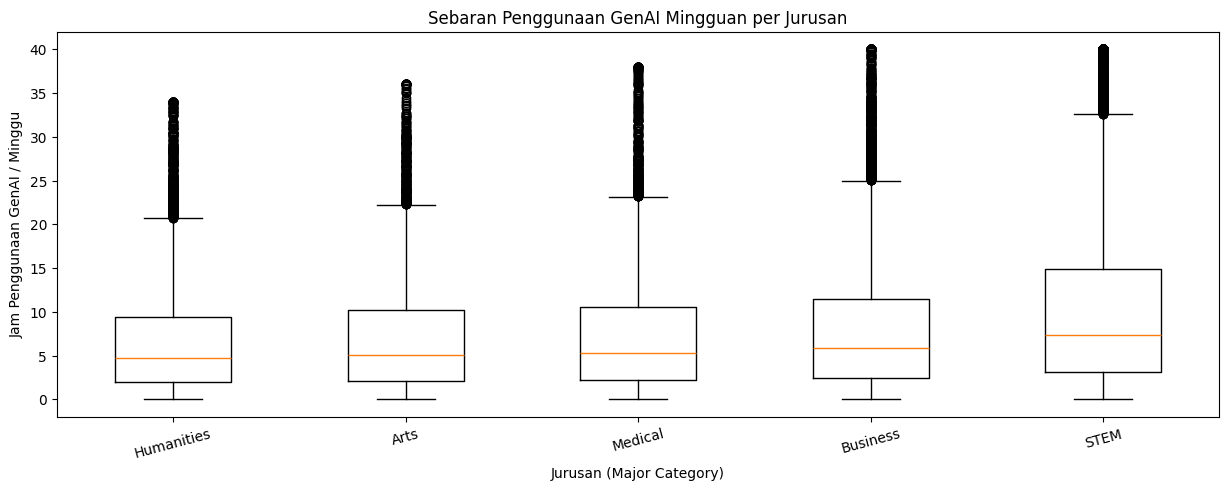

In [ ]:

# Median jam GenAI per jurusan, diurutkan dari yang paling sedikit
median_per_jurusan = df.groupby("Major_Category")["Weekly_GenAI_Hours"].median().sort_values()   #groupby mengelompokkan baris berdasarkan nilai di kolom tertentu
urutan = median_per_jurusan.index
jam_per_jurusan = [df.loc[df["Major_Category"] == k, "Weekly_GenAI_Hours"] for k in urutan]      #sort.values() untuk mengurutkan hasil dari nilai terkecil ke terbesar agar boxplot rapi.
#jam_per_jurusan = [df.loc[df["Major_Category"] == k, "Weekly_GenAI_Hours"] for k in urutan[::-1]]

plt.figure(figsize=(15, 5))                                                                      #untuk membuat "kanvas kosong" dimana diagram akan digambar dan atur size
plt.boxplot(jam_per_jurusan)                                                                     #untuk menggambar boxplot (diagram kotak-garis)
plt.xticks(range(1, len(urutan) + 1), urutan, rotation=15)                                       #untuk mengatur label di sumbu x

# range itu selalu diisi 1 karena label boxplot matplotlib dimulai dari 1, urutan adalah teks yang akan ditampilkan, + 1 karena fungsi range(a,b) menghasilkan angka dari a sampai b dikurangi 1
# rotation=X , untuk miringkan tulisan di sumbu x (jurusan) sebesar X derajat

plt.title("Sebaran Penggunaan GenAI Mingguan per Jurusan")                        #judul
plt.xlabel("Jurusan (Major Category)")                                            #informasi sumbu x
plt.ylabel("Jam Penggunaan GenAI / Minggu")                                       #informasi sumbu y
plt.show()                                                                        #menampilkan diagram


####2f. Heatmap

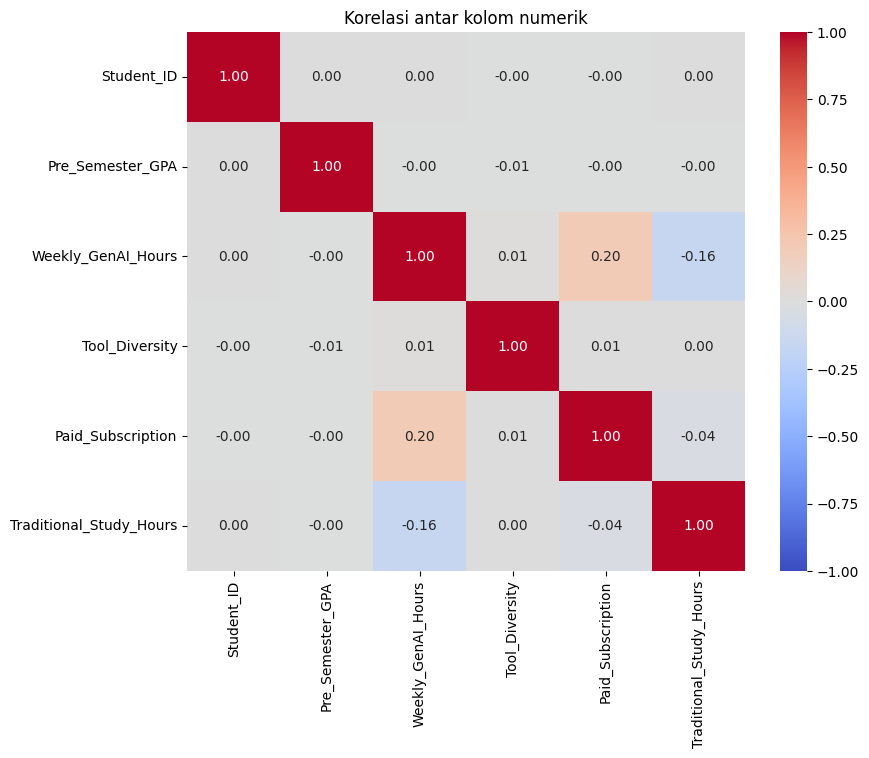

,Weekly_GenAI_Hours
Weekly_GenAI_Hours,1.00
Paid_Subscription,0.20
Tool_Diversity,0.01
Student_ID,0.00
Pre_Semester_GPA,-0.00
Traditional_Study_Hours,-0.16


,Pre_Semester_GPA
Pre_Semester_GPA,1.00
Student_ID,0.00
Paid_Subscription,-0.00
Weekly_GenAI_Hours,-0.00
Traditional_Study_Hours,-0.00
Tool_Diversity,-0.01


In [ ]:
# mengukur seberapa kuat dua kolom yg bergerak bersama dalam garis lurus (bernilai -1 hingga 1)  (!!penjelasan kurang!!)

korelasi = df.corr(numeric_only=True)                       #membuat korelasi dari DataFrame, numeric_only=True agar hanya menampilkan angka numerik

plt.figure(figsize=(9, 7))                                  #membuat "kanvas kosong" yg akan digunakan utk membuat heatmap

sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Korelasi antar kolom numerik")
plt.show()

display(korelasi["Weekly_GenAI_Hours"].sort_values(ascending=False).round(2))    # korelasi Weekly_GenAI_Hours trhdp lainnya
display(korelasi["Pre_Semester_GPA"].sort_values(ascending=False).round(2))

# ascending=False : positif ke negatif

## B. Data Pre-Processing


###1. Data Cleaning


####1a. Membuat salinan dataset utama

In [ ]:
df_clean = df.copy()                                 #membuat salinan baru (duplikat) dari dataset utama (df), lalu menyimpannya ke variabel baru bernama df_clean
print("Ukuran df_clean:", df_clean.shape)            #menampilkan baris dan kolom dari df_clean

Ukuran df_clean: (50000, 10)


####1b. Cek dan hapus baris duplikat

In [ ]:
print("Jumlah data duplikat:", df_clean.duplicated().sum())                      #cek apakah ada duplikat


Jumlah data duplikat: 0


In [ ]:
df_clean = df_clean.drop_duplicates() #hapus data duplikat

print("Jumlah data duplikat:", df_clean.duplicated().sum())                      #cek

Jumlah data duplikat: 0


In [ ]:
# menampilkan contoh bentuk fisik dari baris-baris data yang duplikat

contoh_duplikat = df_clean[df_clean.duplicated(keep=False)]                      # keep=False digunakan untuk menandai semua baris asli dan duplikatnya menjadi True

contoh_duplikat.sort_values(["Major_Category", "Pre_Semester_GPA"]).head(6)
#sort_values() untuk mengurutkan baris berdasarkan dua kolom secara berurutan,   head(6) untuk menampilkan 6 baris dari hasil

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours


In [ ]:
# eksekusi penghapusan duplikat + konfirmasi jumlah baris/kolom terbaru

df_clean = df_clean.drop_duplicates()                             #membuang data duplikat dari df_clean
print("Ukuran setelah duplikat dibuang:", df_clean.shape)         #df_clean.shape untuk menunjukkan baris dan kolom dari DF yang dibersihkan

Ukuran setelah duplikat dibuang: (50000, 10)


####1c. Cari Missing Value

In [ ]:
df_clean.isnull().mean()  #isnull() untuk mencari data yg null atau kosong, mean() untuk mencari mean

,0
Student_ID,0.0
Major_Category,0.0
Year_of_Study,0.0
Pre_Semester_GPA,0.0
Weekly_GenAI_Hours,0.0
Primary_Use_Case,0.0
Prompt_Engineering_Skill,0.0
Tool_Diversity,0.0
Paid_Subscription,0.0
Traditional_Study_Hours,0.0


In [ ]:
#Jika tidak terdapat missing value, maka langsung melakukan duplikat agar tidak ada data yang dihitung dua kali

df_clean.duplicated().sum()                                                      #Membersihkan data duplikat

np.int64(0)

####1d. Validasi data

In [ ]:
# Memastikan semua tipe data kolom sudah sesuai (int, float, atau category/object)

df_clean.dtypes

,0
Student_ID,int64
Major_Category,object
Year_of_Study,object
Pre_Semester_GPA,float64
Weekly_GenAI_Hours,float64
Primary_Use_Case,object
Prompt_Engineering_Skill,object
Tool_Diversity,int64
Paid_Subscription,bool
Traditional_Study_Hours,float64


####1e. Statistik & Deteksi Outlier

In [ ]:
#Mengecek outlier, yaitu nilai yang jauh berbeda dari mayoritas data (nilai ekstrim), agar tidak mengganggu model

df_clean.describe().round(1)

#Menghasilkan ringkasan statistik untuk semua kolom numerik, round(1) untuk membulatkan 1 angka dibelakang koma

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours
count,50000.0,50000.0,50000.0,50000.0,50000.0
mean,125000.5,3.1,8.4,2.8,11.2
std,14433.9,0.5,8.3,1.2,5.2
min,100001.0,1.2,0.0,1.0,1.0
25%,112500.8,2.8,2.4,2.0,7.6
50%,125000.5,3.2,5.8,3.0,11.2
75%,137500.2,3.5,11.7,4.0,14.7
max,150000.0,4.0,40.0,5.0,35.9


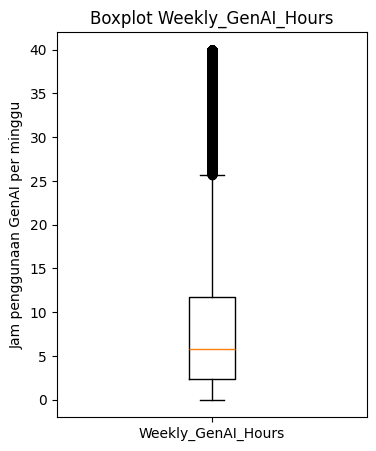

In [ ]:
#Buat diagram boxplot dari data outlier (Weekly_GenAI_Hours)

plt.figure(figsize=(4, 5))                                                       #Membuat kanvas kosong untuk diagram
plt.boxplot(df_clean["Weekly_GenAI_Hours"])                                      #Membuat diagram boxplot
plt.title("Boxplot Weekly_GenAI_Hours")                                          #Untuk judul dari boxplot
plt.ylabel("Jam penggunaan GenAI per minggu")                                    #Informasi sumbu y
plt.xticks([1], ["Weekly_GenAI_Hours"])                                          #informasi sumbu x
plt.show()                                                                       #Menampilkan boxplot

#garis orange: median

# OUTLIER = LINGKARAN HITAM BERDERET DIATAS GARIS KUMIS !

In [ ]:
# Gunakan metode IQR untuk membaca boxplot nya

Q1 = df_clean["Weekly_GenAI_Hours"].quantile(0.25)          #Q1 adalah data yg bernilai 25%
Q3 = df_clean["Weekly_GenAI_Hours"].quantile(0.75)          #Q3 75%

IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_genai = df_clean[(df_clean["Weekly_GenAI_Hours"] < batas_bawah) | (df_clean["Weekly_GenAI_Hours"] > batas_atas)]

print(f"Q1 = {Q1:.1f}, Q3 = {Q3:.1f}, IQR = {IQR:.1f}")
print(f"Batas bawah = {batas_bawah:.1f}, batas atas = {batas_atas:.1f}")
print("Jumlah outlier Weekly_GenAI_Hours:", len(outlier_genai))

Q1 = 2.4, Q3 = 11.7, IQR = 9.3
Batas bawah = -11.6, batas atas = 25.7
Jumlah outlier Weekly_GenAI_Hours: 2583


In [ ]:
# melihat 3 outlier yang paling ekstrem, supaya kamu bisa menilai apakah outlier itu nyata atau salah catat.

outlier_genai.sort_values("Weekly_GenAI_Hours", ascending=False).head(3)

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours
49937,149938,Business,Freshman,3.113,40.0,Direct_Answer_Generation,Intermediate,2,True,14.87
49338,149339,Business,Junior,3.167,40.0,Ideation,Beginner,3,True,8.66
49296,149297,STEM,Sophomore,3.886,40.0,Copywriting/Drafting,Advanced,3,True,8.01


### 2. Data Encoding

####2a. Gambaran visual cara kerja One-Hot Encoding (Major_Category)

In [ ]:
# simulasi/pembuktian bagaimana cara kerja One-Hot Encoding

contoh = df_clean.drop_duplicates(subset="Major_Category")["Major_Category"]
pd.concat([contoh, pd.get_dummies(contoh, dtype=int)], axis=1)

,Major_Category,Arts,Business,Humanities,Medical,STEM
0,Humanities,0,0,1,0,0
1,Medical,0,0,0,1,0
2,Business,0,1,0,0,0
4,STEM,0,0,0,0,1
7,Arts,1,0,0,0,0


####2b. Kolom yang wajib di encode

In [ ]:
# Encode kolom boolean (Paid_Subscription)
df_clean['Paid_Subscription'] = df_clean['Paid_Subscription'].astype(int)


# Encode kolom ordinal (Year_of_Study & Prompt_Engineering_Skill)
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior', 'Graduate']           # Tentukan urutan tingkatannya (order)
skill_order = ['Beginner', 'Intermediate', 'Advanced']

ord_enc = OrdinalEncoder(categories=[year_order, skill_order])
df_clean[['Year_of_Study', 'Prompt_Engineering_Skill']] = ord_enc.fit_transform(
    df_clean[['Year_of_Study', 'Prompt_Engineering_Skill']]
)

# Encode Kolom Nominal (Major_Category & Primary_Use_Case)
df_final = pd.get_dummies(df_clean, columns=['Major_Category', 'Primary_Use_Case'], drop_first=True, dtype=int)

print("Ukuran df_final:", df_final.shape)                                        #tampilkan hasil aplikasi encoding
df_final.head()

Ukuran df_final: (50000, 16)


,Student_ID,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading
0,100001,3.0,2.418,23.31,0.0,1,1,8.13,0,1,0,0,0,0,0,0
1,100002,2.0,3.821,1.12,2.0,5,0,16.65,0,0,1,0,0,0,1,0
2,100003,0.0,3.398,21.26,0.0,2,0,10.35,1,0,0,0,0,0,0,1
3,100004,3.0,3.789,1.82,1.0,4,0,15.23,1,0,0,0,0,0,0,0
4,100005,1.0,3.635,9.29,2.0,4,0,12.55,0,0,0,1,1,0,0,0


####2c. Aplikasi One-Hot Encoding ke seluruh dataset (Major_Category dan Primary_Use_Case)

In [ ]:
# perintah inti encoding yang diterapkan ke seluruh dataset

df_final = pd.get_dummies(df_clean, columns=["Major_Category", "Primary_Use_Case"], drop_first=True, dtype=int)
print("Ukuran df_final:", df_final.shape)
df_final.head()

Ukuran df_final: (50000, 16)


,Student_ID,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading
0,100001,3.0,2.418,23.31,0.0,1,1,8.13,0,1,0,0,0,0,0,0
1,100002,2.0,3.821,1.12,2.0,5,0,16.65,0,0,1,0,0,0,1,0
2,100003,0.0,3.398,21.26,0.0,2,0,10.35,1,0,0,0,0,0,0,1
3,100004,3.0,3.789,1.82,1.0,4,0,15.23,1,0,0,0,0,0,0,0
4,100005,1.0,3.635,9.29,2.0,4,0,12.55,0,0,0,1,1,0,0,0


####2d. Cek status akhir dataset setelah di-encode

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Student_ID                                  50000 non-null  int64  
 1   Year_of_Study                               50000 non-null  float64
 2   Pre_Semester_GPA                            50000 non-null  float64
 3   Weekly_GenAI_Hours                          50000 non-null  float64
 4   Prompt_Engineering_Skill                    50000 non-null  float64
 5   Tool_Diversity                              50000 non-null  int64  
 6   Paid_Subscription                           50000 non-null  int64  
 7   Traditional_Study_Hours                     50000 non-null  float64
 8   Major_Category_Business                     50000 non-null  int64  
 9   Major_Category_Humanities                   50000 non-null  int64  
 10  Major_Cate

In [ ]:
print("Ukuran akhir         :", df_final.shape)
print("Total missing        :", df_final.isnull().sum().sum())
print("Total duplikat       :", df_final.duplicated().sum())
print("Kolom yang bukan angka:", df_final.select_dtypes(exclude="number").columns.tolist())

Ukuran akhir         : (50000, 16)
Total missing        : 0
Total duplikat       : 0
Kolom yang bukan angka: []


##C. Regresi Linear


###0. Pengecekan Ulang

In [ ]:
df_final

,Student_ID,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading
0,100001,3.0,2.418,23.31,0.0,1,1,8.13,0,1,0,0,0,0,0,0
1,100002,2.0,3.821,1.12,2.0,5,0,16.65,0,0,1,0,0,0,1,0
2,100003,0.0,3.398,21.26,0.0,2,0,10.35,1,0,0,0,0,0,0,1
3,100004,3.0,3.789,1.82,1.0,4,0,15.23,1,0,0,0,0,0,0,0
4,100005,1.0,3.635,9.29,2.0,4,0,12.55,0,0,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149996,3.0,2.899,12.16,0.0,2,0,13.36,1,0,0,0,0,0,0,0
49996,149997,3.0,2.870,2.51,1.0,1,0,4.67,0,0,0,1,0,0,0,0
49997,149998,3.0,3.177,15.87,2.0,5,1,3.92,1,0,0,0,0,0,0,1
49998,149999,2.0,3.398,19.91,1.0,5,0,7.10,1,0,0,0,1,0,0,0


###1. Data Splitting

####1a. Pemisahan fitur (X) dan target (Y)
- Dalam kasus ini, targetnya (Y) adalah Pre_Semester_GPA
- Untuk fitur (X), memakai kolom2 yg dipake sebagai prediktor (semua kecuali kolom identitas(ID) dan target itu sendiri)
- Gampangnya, X sebagai soal, Y sebagai kunci jawaban

In [ ]:
# Target kita adalah IPK mahasiswa (Pre_Semester_GPA)

target_column = 'Pre_Semester_GPA'                                               # identifikasi tipe data sebagai target

X = df_final.drop(columns=['Student_ID', target_column])                         # ngedrop yang seharusnya bukan feature (yaitu ID mahasiswa dan target itu sendiri)
y = df_final[target_column]                                                      # kolom target sebagai y (target, variabel independen)

print(f"Jumlah Fitur (X): {X.shape[1]}")                                         # X.shape[1], [0] = jumlah baris, [1] = jumlah kolom
print(f"Jumlah Baris Data: {X.shape[0]}")

Jumlah Fitur (X): 14
Jumlah Baris Data: 50000


####1b. Train test split (80:20)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42                                         # test_size=0.2: bagi jadi 0.8 data latih, 0.2 data uji
)

print(f"Ukuran X_train : {X_train.shape}")
print(f"Ukuran X_test  : {X_test.shape}")

Ukuran X_train : (40000, 14)
Ukuran X_test  : (10000, 14)


####1c. Visualisasi distribusi Train vs Test

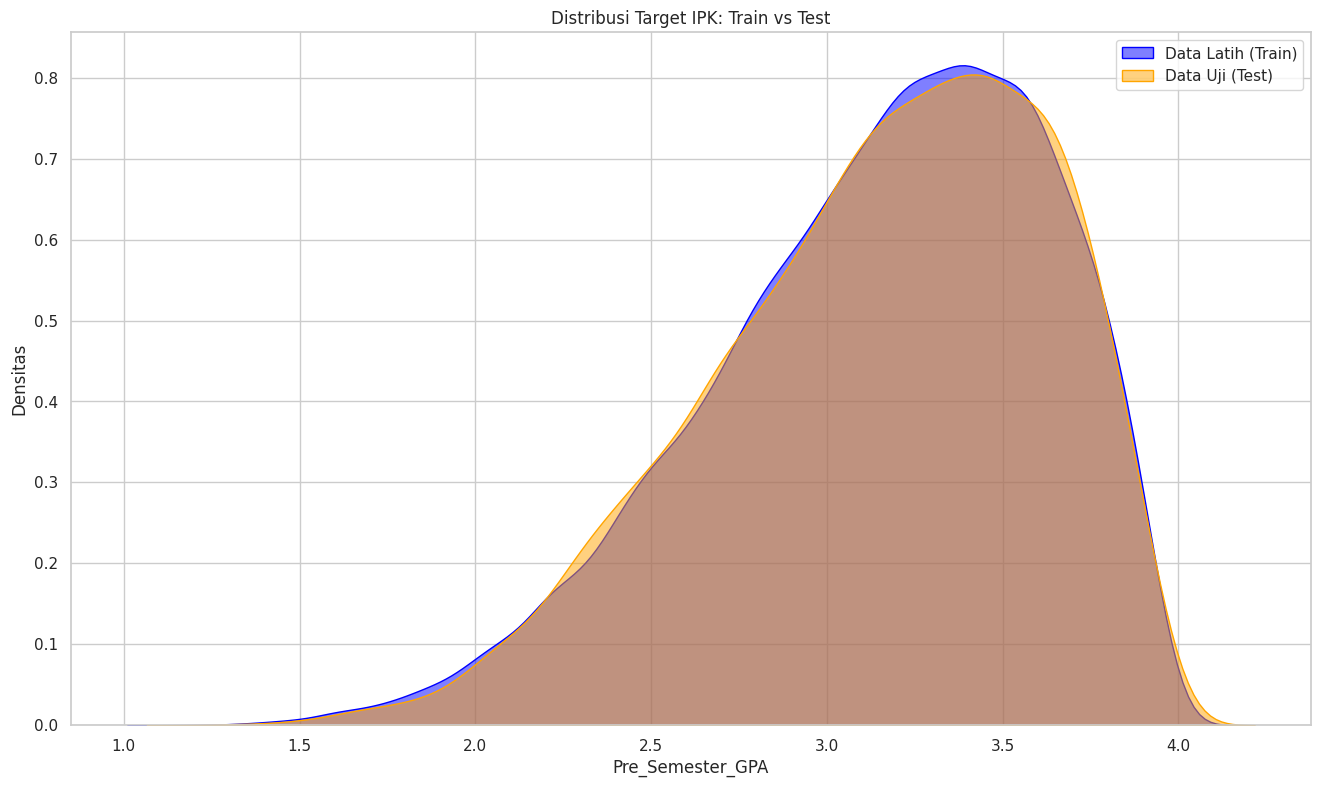

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(16, 9))
sns.kdeplot(y_train, label='Data Latih (Train)', fill=True, color='blue', alpha=0.5)
sns.kdeplot(y_test, label='Data Uji (Test)', fill=True, color='orange', alpha=0.5)

plt.title('Distribusi Target IPK: Train vs Test')
plt.xlabel('Pre_Semester_GPA')
plt.ylabel('Densitas')
plt.legend()
plt.show()

###2. Feature Scaling: Standarisasi

####2a. Inisialisasi StandarScaler

In [ ]:
scaler = StandardScaler()    #StandarScaler sebagai "scaler"

####2b. Scaling pada data uji dan data latih

In [ ]:
X_train_scaled = scaler.fit_transform(X_train)                                   # Hitung mean + standar deviasi (fit) & mentransformasi X_train (transform)

X_test_scaled = scaler.transform(X_test)                                         # Transformasi X_test menggunakan parameter scaler dari X_train (mencegah data leakage)

###3. Model training

####3a. Inisialisasi LinearRegression

In [ ]:
reg = LinearRegression()      #ganti nama jadi reg

print("Nama gw Reg!")

Nama gw Reg!


####3b. Fitting ke data latih

In [ ]:
reg.fit(X_train_scaled, y_train)                       #Melatih Model!
                                                       #X_train_scaled: data latih yang sudah terscaling
print("Model Regresi Linear berhasil dilatih!")

Model Regresi Linear berhasil dilatih!


###4. Prediksi & Evaluasi Model

####4a. Prediksi GPA pada data uji!

In [ ]:
y_pred = reg.predict(X_test_scaled)                    # Melakukan prediksi pada data uji X_test_scaled pakai reg

####4b. Metrik performa prediksi

In [ ]:
mae = mean_absolute_error(y_test, y_pred)                   # hitung MAE

mse = mean_squared_error(y_test, y_pred)                    # hitung MSE

rmse = np.sqrt(mse)                                         # hitung RMSE (akar dari MSE)

r2 = r2_score(y_test, y_pred)                               # hitung R^2

print("======== HASIL EVALUASI PREDIKSI GPA ========")
print(f"MAE  (Rata-rata error absolut)     : {mae:.4f}")
print(f"MSE  (Rata-rata kuadrat error)     : {mse:.4f}")
print(f"RMSE (Akar kuadrat MSE)            : {rmse:.4f}")
print(f"R² Score (Kemampuan variasi model) : {r2:.4f}")

======== HASIL EVALUASI PREDIKSI GPA ========
MAE  (Rata-rata error absolut)     : 0.3899
MSE  (Rata-rata kuadrat error)     : 0.2267
RMSE (Akar kuadrat MSE)            : 0.4761
R² Score (Kemampuan variasi model) : -0.0008


####4c. Visualisasi Seberapa dekat tebakan model

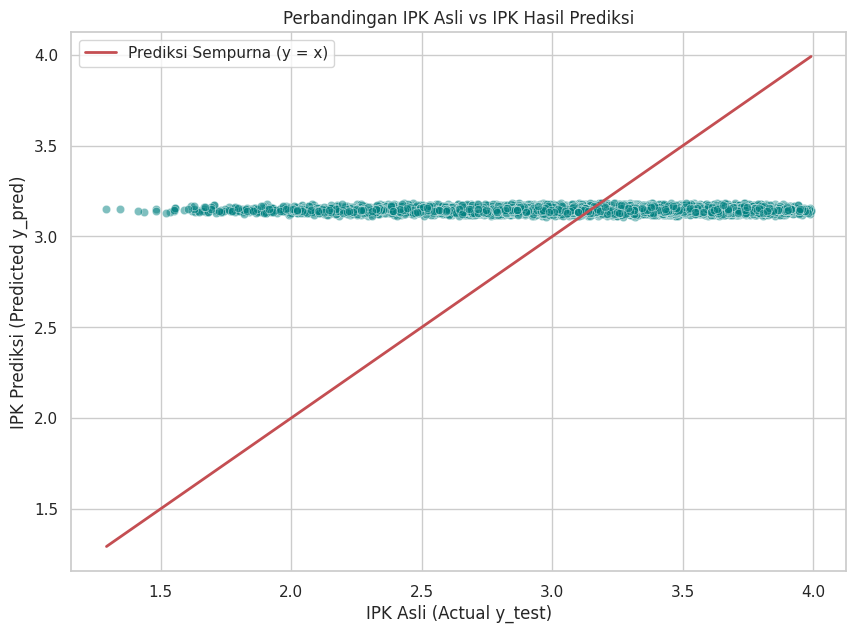

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, color='teal')                                                           # Scatter plot antara nilai asli dan hasil prediksi

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r-', lw=2, label='Prediksi Sempurna (y = x)')   # Garis acuan ideal (y = x)

plt.title('Perbandingan IPK Asli vs IPK Hasil Prediksi')
plt.xlabel('IPK Asli (Actual y_test)')
plt.ylabel('IPK Prediksi (Predicted y_pred)')
plt.legend()
plt.show()

####Keterangan: UNDERFITTING!
- Grafik mendatar diatas adalah tanda keterbatasan sistemik Regresi Linear pada dataset ini.
- Alasan: karena seluruh fitur independen di dataset punya korelasi linear yang SANGAT KECIL terhadap target Pre_Semester_GPA.
- Akibat tidak ditemukannya pola hubungan garis lurus antara fitur dan target, algoritma secara matematis MENGABAIKAN SELURUH VARIABEL PREDIKTOR dengan netapin nilai koefisien/bobot mendekati nol, jadinya model cuma prediksi nilai intersep (IPK rata-rata) untuk setiap observasi.
- udah dispoilerin di heatmap! (terkait korelasi yang sangat kecil)

###5. Analisis hasil regresi linear
- Analisis Faktor Pengaruh Terhadap IPK (Koefisien Regresi)

In [ ]:
coefficients = pd.DataFrame({                                                    # Membuat DataFrame berisi nama fitur dan nilai koefisien regresi
    'Fitur': X.columns,
    'Koefisien': reg.coef_
}).sort_values(by='Koefisien', ascending=False)                                  # Mengurutkan dari koefisien terbesar

print(f"Intersep (IPK Baseline) : {reg.intercept_:.4f}\n")                       # Menampilkan nilai intercept/intersep (nilai baseline IPK)

print("=== Pengaruh Masing-Masing Fitur Terhadap IPK ===")                       # Menampilkan tabel peringkat pengaruh masing-masing fitur terhadap IPK
coefficients

Intersep (IPK Baseline) : 3.1455

=== Pengaruh Masing-Masing Fitur Terhadap IPK ===


,Fitur,Koefisien
11,Primary_Use_Case_Direct_Answer_Generation,0.011238
13,Primary_Use_Case_Summarizing_Reading,0.008284
10,Primary_Use_Case_Debugging/Troubleshooting,0.006277
12,Primary_Use_Case_Ideation,0.005821
3,Tool_Diversity,0.000564
7,Major_Category_Humanities,-0.000216
1,Weekly_GenAI_Hours,-0.001021
0,Year_of_Study,-0.001364
4,Paid_Subscription,-0.001658
8,Major_Category_Medical,-0.002161


####Keterangan:
- Nilai koefisien yang sangat kecil benar2 menunjukan tanda2 underfitting yang JELAS!

###6. Uji Prediksi Manual!!!!!!!!

####6a. Masukkin data

In [ ]:
#______________________MEMINTA INPUT INTERAKTIF DARI PENGGUNA________________________

print("MASUKIN DATA MAHASISWA YANG MAU DIPREDIKSI!")

year_study = float(input("Year of Study (0: Freshman, 1: Sophomore, 2: Junior, 3: Senior, 4: Graduate):\n"))


genai_hours = float(input("\nWeekly GenAI Hours (Jam per minggu):\n"))


prompt_skill = float(input("\nPrompt Engineering Skill (0: Beginner, 1: Intermediate, 2: Advanced):\n"))


tool_div = int(input("\nTool Diversity (Jumlah tool AI yg dipake):\n"))


paid_sub = int(input("\nPaid Subscription (1: Ya (Langganan), 0: Tidak):\n"))


study_hours = float(input("\nTraditional Study Hours (Jam belajar non-AI per minggu):\n"))


jurusan_choice = input("\nPilihan Jurusan (1. Business, 2. Humanities, 3. Medical, 4. STEM, 5. Lainnya):\n")


use_case_choice = input("\nPilih Penggunaan Utama GenAI (1. Debugging/Troubleshooting, 2. Direct Answer Generation, 3. Ideation, 4. Summarizing/Reading, 5. Lainnya):\n")


# ________________________MENYUSUN DATAFRAME BERDASARKAN INPUT________________________

data_baru = pd.DataFrame([{
    'Year_of_Study': year_study,                                                 # Tahun angkatan kuliah
    'Weekly_GenAI_Hours': genai_hours,                                           # Jam penggunaan GenAI per minggu
    'Prompt_Engineering_Skill': prompt_skill,                                    # Tingkat kemampuan prompt engineering
    'Tool_Diversity': tool_div,                                                  # Jumlah variasi tool yang digunakan
    'Paid_Subscription': paid_sub,                                               # Status langganan berbayar (1/0)
    'Traditional_Study_Hours': study_hours,                                      # Jam belajar tradisional per minggu


    # Logika One-Hot Encoding Jurusan (otomatis bernilai 1 jika dipilih, lainnya 0)

    'Major_Category_Business': 1 if jurusan_choice == '1' else 0,                # 1 jika jurusan Business, 0 jika bukan
    'Major_Category_Humanities': 1 if jurusan_choice == '2' else 0,              # 1 jika jurusan Humanities, 0 jika bukan
    'Major_Category_Medical': 1 if jurusan_choice == '3' else 0,                 # 1 jika jurusan Medical, 0 jika bukan
    'Major_Category_STEM': 1 if jurusan_choice == '4' else 0,                    # 1 jika jurusan STEM, 0 jika bukan



    # Logika One-Hot Encoding Use Case (otomatis bernilai 1 jika dipilih, lainnya 0)

    'Primary_Use_Case_Debugging/Troubleshooting': 1 if use_case_choice == '1' else 0,      # 1 jika untuk debugging, 0 jika bukan
    'Primary_Use_Case_Direct_Answer_Generation': 1 if use_case_choice == '2' else 0,       # 1 jika untuk cari jawaban langsung, 0 jika bukan
    'Primary_Use_Case_Ideation': 1 if use_case_choice == '3' else 0,                       # 1 jika untuk curah ide, 0 jika bukan
    'Primary_Use_Case_Summarizing_Reading': 1 if use_case_choice == '4' else 0             # 1 jika untuk merangkum bacaan, 0 jika bukan
}])


# Memastikan urutan kolom data_baru sama persis dengan urutan kolom X

data_baru = data_baru[X.columns]

MASUKIN DATA MAHASISWA YANG MAU DIPREDIKSI!
Year of Study (0: Freshman, 1: Sophomore, 2: Junior, 3: Senior, 4: Graduate):
4

Weekly GenAI Hours (Jam per minggu):
44

Prompt Engineering Skill (0: Beginner, 1: Intermediate, 2: Advanced):
2

Tool Diversity (Jumlah tool AI yg dipake):
4

Paid Subscription (1: Ya (Langganan), 0: Tidak):
1

Traditional Study Hours (Jam belajar non-AI per minggu):
23

Pilihan Jurusan (1. Business, 2. Humanities, 3. Medical, 4. STEM, 5. Lainnya):
1

Pilih Penggunaan Utama GenAI (1. Debugging/Troubleshooting, 2. Direct Answer Generation, 3. Ideation, 4. Summarizing/Reading, 5. Lainnya):
3


In [ ]:
# data_baru = pd.DataFrame([{
#     'Year_of_Study': 3.0,                                                        # 0: Freshman, 1: Sophomore, 2: Junior, 3: Senior, 4: Graduate
#     'Weekly_GenAI_Hours': 15.5,                                                  # Jam penggunaan GenAI per minggu
#     'Prompt_Engineering_Skill': 2.0,                                             # 0: Beginner, 1: Intermediate, 2: Advanced
#     'Tool_Diversity': 3,                                                         # Jumlah variasi tool yang dipakai
#     'Paid_Subscription': 1,                                                      # 1: Ya (Langganan), 0: Tidak
#     'Traditional_Study_Hours': 12.0,                                             # Jam belajar tradisional per minggu
#     'Major_Category_Business': 0,                                                # 1 jika jurusan Business, 0 jika bukan
#     'Major_Category_Humanities': 0,                                              # 1 jika jurusan Humanities, 0 jika bukan
#     'Major_Category_Medical': 0,                                                 # 1 jika jurusan Medical, 0 jika bukan
#     'Major_Category_STEM': 1,                                                    # 1 jika jurusan STEM, 0 jika bukan

#     # Di data, hanya bisa satu saja pilih penggunaan GenAI (salah satu bernilai 1, lainnya 0)

#     'Primary_Use_Case_Debugging/Troubleshooting': 1,                             # 1 jika tujuan utama GenAI untuk debugging, 0 jika bukan
#     'Primary_Use_Case_Direct_Answer_Generation': 0,                              # 1 jika tujuan utama GenAI untuk cari jawaban langsung, 0 jika bukan
#     'Primary_Use_Case_Ideation': 0,                                              # 1 jika tujuan utama GenAI untuk curah ide, 0 jika bukan
#     'Primary_Use_Case_Summarizing_Reading': 0                                    # 1 jika tujuan utama GenAI untuk merangkum bacaan, 0 jika bukan
# }])

# data_baru = data_baru[X.columns]

####6b. Scaling dan Prediksi !!!!!

In [ ]:
data_baru_scaled = scaler.transform(data_baru)

ipk_prediksi = reg.predict(data_baru_scaled)[0]

print("=== HASIL UJI COBA PREDIKSI IPK MAHASISWA BARU ===")
print(f"Estimasi Prediksi IPK : {ipk_prediksi:.2f}")

=== HASIL UJI COBA PREDIKSI IPK MAHASISWA BARU ===
Estimasi Prediksi IPK : 3.12


##D. Random Forest

##E. Membandingkan Dua Model ML

##F. Rangkuman, Kesimpulan, dan Rekomendasi